# 02 - DESI-only Symbolic Regression

## Objective

Use PySR to reconstruct the DESI DR2 radial BAO observable

$$
\widetilde{D}_H(z) \equiv \frac{D_H(z)}{r_d},
$$

and compare the independently recovered expression with the paper result

$$
\frac{D_H(z)}{r_d} = 28.4\exp(-0.519z).
$$

This notebook uses the validated six-point dataset exported by notebook 01. It performs two clearly labelled analyses:

1. `public_full`: the full public DESI Gaussian covariance.
2. `paper_table`: a diagonal covariance constructed from the rounded Table I uncertainties.

It also reconstructs the central $w(z)$ curve from the selected expression. Monte Carlo confidence intervals are deferred to notebook 03.

> **Reproduction limitation.** The paper specifies the operator set, covariance-weighted loss, and PySR `best` selection criterion, but it does not report the PySR iteration count, population settings, or random seed. The adopted values below are therefore independent reproduction settings, not claimed paper settings.


## 1. Imports and software versions

The first PySR import starts the Julia backend. On a new computer this can take several minutes because Julia dependencies are installed and precompiled once.


In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import sympy as sp
from pysr import PySRRegressor, jl

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

SOFTWARE_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": metadata.version("scipy"),
    "sympy": sp.__version__,
    "pysr": metadata.version("pysr"),
    "julia": str(jl.seval("string(VERSION)")),
}

display(pd.Series(SOFTWARE_VERSIONS, name="version").to_frame())

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


,version
python,3.13.11
numpy,2.5.2
pandas,2.3.3
scipy,1.18.1
sympy,1.14.0
pysr,1.5.9
julia,1.12.7


## 2. Locate the project and load notebook 01 output

The project-root search allows the notebook to run from either the project root or the `notebooks/` directory. Raw DESI files are not read or modified here.


In [2]:
def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the processed DESI dataset."""
    for candidate in (start, *start.parents):
        expected = candidate / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
        if expected.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate results/01_desi_data_check/desi_dr2_dh_over_rd.npz. "
        "Run notebook 01 first."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_FILE = PROJECT_ROOT / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
EXPERIMENT_ID = "unrestricted_5seeds_20260905"
RESULTS_DIR = PROJECT_ROOT / "results" / "02_desi_pysr"
EXPERIMENT_DIR = RESULTS_DIR / EXPERIMENT_ID
UNRESTRICTED_RUNS_DIR = EXPERIMENT_DIR / "runs"
EXPERIMENT_FIGURES_DIR = EXPERIMENT_DIR / "figures"

for directory in (
    RESULTS_DIR,
    EXPERIMENT_DIR,
    UNRESTRICTED_RUNS_DIR,
    EXPERIMENT_FIGURES_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

with np.load(INPUT_FILE) as data:
    z = data["z"].astype(float)
    y = data["y"].astype(float)
    public_covariance = data["covariance"].astype(float)
    public_sigma = data["sigma"].astype(float)
    tracers = data["tracers"].astype(str)

X = z.reshape(-1, 1)

print(f"Project root: {PROJECT_ROOT}")
print(f"Input file: {INPUT_FILE}")
print(f"Number of DESI radial BAO measurements: {len(z)}")

Project root: /Users/kemingliu/Desktop/Dark Energy
Input file: /Users/kemingliu/Desktop/Dark Energy/results/01_desi_data_check/desi_dr2_dh_over_rd.npz
Number of DESI radial BAO measurements: 6


## 3. Validate the processed dataset

These checks prevent symbolic regression from running on an incorrectly ordered or invalid dataset.


In [3]:
N_DATA = 6

assert z.shape == (N_DATA,)
assert y.shape == (N_DATA,)
assert public_sigma.shape == (N_DATA,)
assert tracers.shape == (N_DATA,)
assert public_covariance.shape == (N_DATA, N_DATA)
assert np.isfinite(z).all() and np.isfinite(y).all()
assert np.isfinite(public_covariance).all()
assert np.all(np.diff(z) > 0.0), "Redshifts must be strictly increasing."
assert np.allclose(public_covariance, public_covariance.T, rtol=0.0, atol=1e-12)
assert np.linalg.eigvalsh(public_covariance).min() > 0.0
assert np.allclose(public_sigma, np.sqrt(np.diag(public_covariance)))

desi_table = pd.DataFrame(
    {
        "tracer": tracers,
        "z": z,
        "DH_over_rd": y,
        "public_sigma": public_sigma,
    }
)

print("Processed DESI dataset validation: PASSED")
display(desi_table)

Processed DESI dataset validation: PASSED


,tracer,z,DH_over_rd,public_sigma
0,LRG1,0.510000,21.862947,0.428868
1,LRG2,0.706000,19.455349,0.333870
2,LRG3+ELG1,0.934000,17.641495,0.201043
3,ELG2,1.321000,14.176022,0.224551
4,QSO,1.484000,12.817000,0.518012
5,Ly-alpha,2.330000,8.631546,0.101062


## 4. Define the two covariance configurations

The public covariance preserves the correlations in the DESI Gaussian likelihood. The paper-table covariance is a sensitivity test constructed as

$$
C_{\mathrm{table}}=\operatorname{diag}(\sigma_{\mathrm{Table\ I}}^2).
$$

The two choices are never mixed within one loss evaluation.


In [4]:
PAPER_TABLE_SIGMA = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])
paper_table_covariance = np.diag(PAPER_TABLE_SIGMA**2)

COVARIANCE_CONFIGS = {
    "public_full": public_covariance,
    "paper_table": paper_table_covariance,
}

sigma_comparison = desi_table.copy()
sigma_comparison["paper_sigma"] = PAPER_TABLE_SIGMA
sigma_comparison["relative_difference_percent"] = (
    100.0 * (public_sigma - PAPER_TABLE_SIGMA) / PAPER_TABLE_SIGMA
)

for name, covariance in COVARIANCE_CONFIGS.items():
    assert covariance.shape == (N_DATA, N_DATA)
    assert np.allclose(covariance, covariance.T)
    assert np.linalg.eigvalsh(covariance).min() > 0.0

display(sigma_comparison)
print(
    "Maximum public-vs-paper uncertainty difference: "
    f"{sigma_comparison['relative_difference_percent'].abs().max():.2f}%"
)

,tracer,z,DH_over_rd,public_sigma,paper_sigma,relative_difference_percent
0,LRG1,0.510000,21.862947,0.428868,0.425000,0.910194
1,LRG2,0.706000,19.455349,0.333870,0.330000,1.172737
2,LRG3+ELG1,0.934000,17.641495,0.201043,0.193000,4.167486
3,ELG2,1.321000,14.176022,0.224551,0.221000,1.606946
4,QSO,1.484000,12.817000,0.518012,0.516000,0.389878
5,Ly-alpha,2.330000,8.631546,0.101062,0.101000,0.061835


Maximum public-vs-paper uncertainty difference: 4.17%


## 5. Deterministic exponential baseline

Before the stochastic PySR search, fit the same two-parameter family as the published result:

$$
f(z)=A\exp(Bz).
$$

The covariance-weighted statistic is

$$
\chi^2=\mathbf{r}^{T}C^{-1}\mathbf{r},
\qquad
\mathcal{L}=\frac{\chi^2}{n}.
$$

This baseline tests the effect of the covariance choice independently of symbolic model search.


In [5]:
def exponential_model(redshift, amplitude, slope):
    """Evaluate A * exp(B z)."""
    return amplitude * np.exp(slope * redshift)


def chi_square(observed, predicted, covariance):
    """Return r.T @ C^-1 @ r without explicitly forming C^-1."""
    residual = np.asarray(predicted) - np.asarray(observed)
    return float(residual @ np.linalg.solve(covariance, residual))


PAPER_REFERENCE_PARAMETERS = np.array([28.4, -0.519])
paper_reference_prediction = exponential_model(z, *PAPER_REFERENCE_PARAMETERS)

baseline_rows = []
baseline_parameters = {}

for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    fitted_parameters, parameter_covariance = curve_fit(
        exponential_model,
        z,
        y,
        p0=PAPER_REFERENCE_PARAMETERS,
        sigma=covariance,
        absolute_sigma=True,
        maxfev=20_000,
    )
    fitted_prediction = exponential_model(z, *fitted_parameters)
    fitted_chi2 = chi_square(y, fitted_prediction, covariance)
    paper_chi2 = chi_square(y, paper_reference_prediction, covariance)
    baseline_parameters[covariance_name] = fitted_parameters
    baseline_rows.append(
        {
            "covariance": covariance_name,
            "A_fit": fitted_parameters[0],
            "B_fit": fitted_parameters[1],
            "chi2_fit": fitted_chi2,
            "loss_fit": fitted_chi2 / N_DATA,
            "chi2_paper_expression": paper_chi2,
            "loss_paper_expression": paper_chi2 / N_DATA,
        }
    )

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results)

,covariance,A_fit,B_fit,chi2_fit,loss_fit,chi2_paper_expression,loss_paper_expression
0,public_full,28.120222,-0.508294,2.444247,0.407375,4.222491,0.703749
1,paper_table,28.129755,-0.508460,2.529349,0.421558,4.299756,0.716626


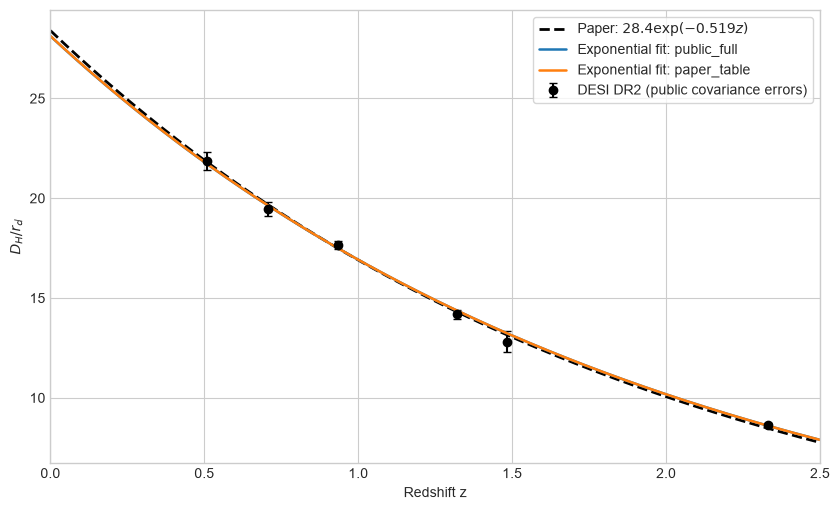

Saved: /Users/kemingliu/Desktop/Dark Energy/results/02_desi_pysr/unrestricted_5seeds_20260905/figures/exponential_baseline.png


In [6]:
z_plot = np.linspace(0.0, 2.5, 500)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.errorbar(
    z,
    y,
    yerr=public_sigma,
    fmt="o",
    color="black",
    capsize=3,
    label="DESI DR2 (public covariance errors)",
)
ax.plot(
    z_plot,
    exponential_model(z_plot, *PAPER_REFERENCE_PARAMETERS),
    "k--",
    linewidth=2.0,
    label=r"Paper: $28.4\exp(-0.519z)$",
)

colors = {"public_full": "tab:blue", "paper_table": "tab:orange"}
for covariance_name, fitted_parameters in baseline_parameters.items():
    ax.plot(
        z_plot,
        exponential_model(z_plot, *fitted_parameters),
        color=colors[covariance_name],
        linewidth=1.8,
        label=f"Exponential fit: {covariance_name}",
    )

ax.set(xlabel="Redshift z", ylabel=r"$D_H/r_d$", xlim=(0.0, 2.5))
ax.legend(frameon=True)
fig.tight_layout()

BASELINE_FIGURE = EXPERIMENT_FIGURES_DIR / "exponential_baseline.png"
fig.savefig(BASELINE_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved: {BASELINE_FIGURE}")

### Interpretation of the exponential baseline fit

We fitted the fixed functional form $f(z)=A\exp(Bz)$ to the six DESI measurements using two covariance choices.

With the public covariance, the best-fit parameters are $A=28.1202$ and $B=-0.508294$, with $\chi^2=2.444$. With six measurements and two fitted parameters, the number of degrees of freedom is $\nu=4$, giving a reduced chi-square of $\chi^2/\nu=0.611$. The corresponding value for the Table I covariance is $0.632$. These results show no clear evidence of a poor fit under the assumed Gaussian errors. Note that the reported `loss_fit` is $\chi^2/6$, not the reduced chi-square.

The fitted parameters are close to the published values, $A=28.4$ and $B=-0.519$. Under the public covariance, the published expression gives $\chi^2=4.222$, compared with $2.444$ after refitting. A lower chi-square is expected when the parameters are optimized for the current data and covariance; this improvement alone does not establish an inconsistency with the paper.

Changing from the public covariance to the Table I covariance shifts $A$ by approximately $0.00953$ and $B$ by $-0.000166$. These shifts are small compared with the approximate parameter uncertainties of $0.39$ and $0.0093$, respectively. Thus, the best-fit exponential parameters are relatively insensitive to these two covariance choices.

This test evaluates the fit of a predefined exponential model. It does not establish that PySR independently selects this functional form, explain the discrepancy between the two uncertainty sources, or reproduce the paper's full analysis.

## 6. PySR reproduction configuration

### Settings stated in the paper

- Unary operators: `log`, `sqrt`, `exp`, `square`, `cube`.
- Binary operators: `+`, `-`, `*`, `/`, `^` (`pow` in the paper table).
- Full covariance-weighted loss.
- Model selection: `best`.

### Independent settings adopted here

The iteration count, population settings, and seeds below are recorded because the paper does not report them. Two seeds are used to expose stochastic variation. Increase `NITERATIONS` for a deeper search; do not interpret a short run as proof of exact reproduction.


In [7]:
RUN_PYSR = True

PRIMARY_SEED = 42
ROBUSTNESS_SEEDS = (202502, 202503, 202504, 202505, 202506)
REPRODUCTION_COVARIANCE = "paper_table"
NITERATIONS = 60
POPULATIONS = 8
POPULATION_SIZE = 30
MAXSIZE = 18
PAPER_LIKE_NITERATIONS = 120
PAPER_LIKE_MAXSIZE = 7

PYSR_SETTINGS = {
    "model_selection": "best",
    "binary_operators": ["+", "-", "*", "/", "^"],
    "unary_operators": ["log", "sqrt", "exp", "square", "cube"],
    "constraints": {"^": (-1, 1)},
    "niterations": NITERATIONS,
    "populations": POPULATIONS,
    "population_size": POPULATION_SIZE,
    "maxsize": MAXSIZE,
    "ncycles_per_iteration": 300,
    "precision": 64,
    "parallelism": "serial",
    "deterministic": True,
    "progress": False,
    "verbosity": 0,
}

PAPER_LIKE_SETTINGS = {
    **PYSR_SETTINGS,
    "niterations": PAPER_LIKE_NITERATIONS,
    "maxsize": PAPER_LIKE_MAXSIZE,
}

display(pd.Series(PYSR_SETTINGS, name="adopted value").to_frame())

,adopted value
model_selection,best
binary_operators,"[+, -, *, /, ^]"
unary_operators,"[log, sqrt, exp, square, cube]"
constraints,"{'^': (-1, 1)}"
niterations,60
populations,8
population_size,30
maxsize,18
ncycles_per_iteration,300
precision,64


## 7. Implement the full covariance loss

PySR normally applies an element-by-element loss. Correlated data require a full objective evaluated on the entire residual vector:

$$
\mathcal{L}=\frac{1}{n}\mathbf{r}^{T}C^{-1}\mathbf{r}.
$$

The inverse covariance is embedded in the Julia objective separately for each run. The Python validation later recomputes the same statistic independently.


In [9]:
def make_julia_covariance_loss(covariance):
    """Create a Julia full-objective string for one fixed covariance matrix."""
    inverse_covariance = np.linalg.inv(covariance)
    matrix_rows = [
        " ".join(f"{value:.17g}" for value in row)
        for row in inverse_covariance
    ]
    matrix_literal = ";\n        ".join(matrix_rows)
    return f"""
function covariance_loss(tree, dataset::Dataset{{T,L}}, options)::L where {{T,L}}
    prediction, flag = eval_tree_array(tree, dataset.X, options)
    if !flag || any(value -> !isfinite(value), prediction)
        return L(Inf)
    end
    residual = prediction .- dataset.y
    inverse_covariance = T[
        {matrix_literal}
    ]
    return L(sum(residual .* (inverse_covariance * residual)) / dataset.n)
end
"""


for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    loss_source = make_julia_covariance_loss(covariance)
    assert "inverse_covariance" in loss_source
    print(f"Prepared full covariance objective: {covariance_name}")

Prepared full covariance objective: public_full
Prepared full covariance objective: paper_table


## 8. Run the PySR experiments

Ten searches are performed: two covariance choices times five predetermined random seeds. All outputs are stored under an experiment-specific directory so that earlier experiments are not overwritten.

The selected equation is the result of PySR's `best` criterion, not simply the lowest-loss expression.


In [ ]:
# Keep the summary, candidates, and raw PySR runs together for this experiment.
SUMMARY_FILE = EXPERIMENT_DIR / "summary.csv"
CANDIDATES_FILE = EXPERIMENT_DIR / "candidates.csv"

summary_rows = []
candidate_frames = []
pysr_summary = pd.DataFrame()
pysr_candidates = pd.DataFrame()

if RUN_PYSR:
    for covariance_name, covariance in COVARIANCE_CONFIGS.items():
        for seed in ROBUSTNESS_SEEDS:
            print(f"Running PySR: covariance={covariance_name}, seed={seed}")
            run_id = f"{covariance_name}_seed_{seed}"
            model = PySRRegressor(
                **PYSR_SETTINGS,
                random_state=seed,
                loss_function=make_julia_covariance_loss(covariance),
                output_directory=str(UNRESTRICTED_RUNS_DIR),
                run_id=run_id,
            )
            model.fit(X, y, variable_names=["z"])

            selected = model.get_best()
            selected_index = int(selected.name)
            prediction = np.asarray(
                model.predict(X, index=selected_index), dtype=float
            ).reshape(-1)
            selected_chi2 = chi_square(y, prediction, covariance)

            equations = model.equations_.copy()
            equations["covariance"] = covariance_name
            equations["seed"] = seed
            equations["run_id"] = run_id
            equations["selected_by_best"] = equations.index == selected_index
            if "sympy_format" in equations:
                equations["sympy_format"] = equations["sympy_format"].astype(str)
            drop_columns = [
                name
                for name in ("lambda_format", "jax_format", "torch_format")
                if name in equations.columns
            ]
            candidate_frames.append(equations.drop(columns=drop_columns))

            summary_rows.append(
                {
                    "covariance": covariance_name,
                    "seed": seed,
                    "run_id": run_id,
                    "selected_index": selected_index,
                    "complexity": int(selected["complexity"]),
                    "pysr_loss": float(selected["loss"]),
                    "python_chi2": selected_chi2,
                    "python_loss": selected_chi2 / N_DATA,
                    "equation": str(selected["equation"]),
                    "sympy_expression": str(selected["sympy_format"]),
                }
            )
            print(f"Selected expression: {selected['sympy_format']}")

    pysr_summary = pd.DataFrame(summary_rows)
    pysr_candidates = pd.concat(candidate_frames, ignore_index=True)
    pysr_summary.to_csv(SUMMARY_FILE, index=False)
    pysr_candidates.to_csv(CANDIDATES_FILE, index=False)
else:
    if not SUMMARY_FILE.is_file() or not CANDIDATES_FILE.is_file():
        raise FileNotFoundError(
            "RUN_PYSR is False, but saved PySR result tables were not found."
        )
    pysr_summary = pd.read_csv(SUMMARY_FILE)
    pysr_candidates = pd.read_csv(CANDIDATES_FILE)

display(pysr_summary)
print(f"Saved summary: {SUMMARY_FILE}")
print(f"Saved candidate equations: {CANDIDATES_FILE}")

## 9. Targeted low-complexity reproduction

The unrestricted `best` criterion can select a highly flexible expression that interpolates six measurements but extrapolates poorly toward $z=0$. This is especially important because $w(z)$ requires a derivative outside the lowest observed redshift, $z=0.51$.

The paper's published expression is a low-complexity exponential. We therefore run a separate, explicitly labelled search with `maxsize=7`, the smallest value accepted by PySR 1.5.9. This is a targeted reproduction diagnostic, not an assertion that the authors used this unreported limit. The unrestricted searches above remain saved as the direct test of the stated `best` criterion.


In [11]:
# Section 9 uses its own experiment directory and can be run without Section 8.
TARGETED_EXPERIMENT_ID = (
    f"targeted_maxsize{PAPER_LIKE_MAXSIZE}_seed{PRIMARY_SEED}_20260906"
)
TARGETED_EXPERIMENT_DIR = RESULTS_DIR / TARGETED_EXPERIMENT_ID
TARGETED_RUNS_DIR = TARGETED_EXPERIMENT_DIR / "runs"
PAPER_LIKE_FILE = TARGETED_EXPERIMENT_DIR / "summary.csv"
TARGETED_CONFIGURATION_FILE = TARGETED_EXPERIMENT_DIR / "configuration.json"

TARGETED_RUNS_DIR.mkdir(parents=True, exist_ok=True)
paper_like_rows = []

if RUN_PYSR:
    for covariance_name, covariance in COVARIANCE_CONFIGS.items():
        run_id = f"{covariance_name}_seed_{PRIMARY_SEED}_maxsize_{PAPER_LIKE_MAXSIZE}"
        print(
            "Running targeted low-complexity PySR: "
            f"covariance={covariance_name}, seed={PRIMARY_SEED}"
        )
        model = PySRRegressor(
            **PAPER_LIKE_SETTINGS,
            random_state=PRIMARY_SEED,
            loss_function=make_julia_covariance_loss(covariance),
            output_directory=str(TARGETED_RUNS_DIR),
            run_id=run_id,
        )
        model.fit(X, y, variable_names=["z"])

        selected = model.get_best()
        selected_index = int(selected.name)
        prediction = np.asarray(
            model.predict(X, index=selected_index), dtype=float
        ).reshape(-1)
        selected_chi2 = chi_square(y, prediction, covariance)
        paper_like_rows.append(
            {
                "covariance": covariance_name,
                "seed": PRIMARY_SEED,
                "run_id": run_id,
                "maxsize": PAPER_LIKE_MAXSIZE,
                "complexity": int(selected["complexity"]),
                "pysr_loss": float(selected["loss"]),
                "python_chi2": selected_chi2,
                "python_loss": selected_chi2 / N_DATA,
                "equation": str(selected["equation"]),
                "sympy_expression": str(selected["sympy_format"]),
            }
        )
        print(f"Selected low-complexity expression: {selected['sympy_format']}")

    paper_like_summary = pd.DataFrame(paper_like_rows)
    paper_like_summary.to_csv(PAPER_LIKE_FILE, index=False)
else:
    if not PAPER_LIKE_FILE.is_file():
        raise FileNotFoundError(
            "RUN_PYSR is False, but the targeted low-complexity table was not found."
        )
    paper_like_summary = pd.read_csv(PAPER_LIKE_FILE)

targeted_configuration = {
    "experiment_id": TARGETED_EXPERIMENT_ID,
    "purpose": "Targeted low-complexity sensitivity test",
    "seed": PRIMARY_SEED,
    "settings": PAPER_LIKE_SETTINGS,
    "covariance_configurations": list(COVARIANCE_CONFIGS),
}
with TARGETED_CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(targeted_configuration, stream, indent=2)

display(paper_like_summary)
print(f"Saved targeted low-complexity summary: {PAPER_LIKE_FILE}")
print(f"Saved targeted configuration: {TARGETED_CONFIGURATION_FILE}")

Running targeted low-complexity PySR: covariance=public_full, seed=42
Selected low-complexity expression: exp(z/(-1.967363705794148) + 3.336488976727047)
Running targeted low-complexity PySR: covariance=paper_table, seed=42
Selected low-complexity expression: 45.641250344062/(sqrt(z**3) + 1.7131954048188751)


,covariance,seed,run_id,maxsize,complexity,pysr_loss,python_chi2,python_loss,equation,sympy_expression
0,public_full,42,public_full_seed_42_maxsize_7,7,6,0.407375,2.444247,0.407375,exp((z / -1.967363705794148) + 3.336488976727047),exp(z/(-1.967363705794148) + 3.336488976727047)
1,paper_table,42,paper_table_seed_42_maxsize_7,7,7,0.385125,2.310748,0.385125,45.641250344062 / (sqrt(cube(z)) + 1.713195404...,45.641250344062/(sqrt(z**3) + 1.7131954048188751)


Saved targeted low-complexity summary: /Users/kemingliu/Desktop/Dark Energy/results/02_desi_pysr/targeted_maxsize7_seed42_20260906/summary.csv
Saved targeted configuration: /Users/kemingliu/Desktop/Dark Energy/results/02_desi_pysr/targeted_maxsize7_seed42_20260906/configuration.json


## 10. Inspect the candidate equations

The paper's Appendix A reports candidate complexity and loss, so the independent run preserves the same information. Stochastic runs are expected to differ even with identical data and operators.


In [ ]:
candidate_columns = [
    column
    for column in (
        "covariance",
        "seed",
        "complexity",
        "loss",
        "score",
        "equation",
        "selected_by_best",
    )
    if column in pysr_candidates.columns
]

display(
    pysr_candidates[candidate_columns]
    .sort_values(["covariance", "seed", "complexity"])
    .reset_index(drop=True)
)

paper_table_candidates = pd.DataFrame(
    {
        "complexity": [1, 2, 3, 4, 5, 7, 8, 9, 11, 13, 15, 16, 17],
        "paper_loss": [
            2519.06,
            120.73,
            91.50,
            1.22,
            0.30,
            0.25,
            0.24,
            0.21,
            0.17,
            0.05,
            0.02,
            0.015,
            0.013,
        ],
    }
)

print("Published DESI-only losses from Appendix A (for scale comparison):")
display(paper_table_candidates)

## 11. Compare the selected PySR expressions with the paper result

Both targeted low-complexity results are retained. With the fixed seed used here, only the `paper_table` configuration recovers the published exponential structure, so it is labelled the paper-like reproduction for the central $w(z)$ comparison. The `public_full` result remains an equally important covariance-sensitivity result and is saved separately.


In [ ]:
z_symbol = sp.Symbol("z", real=True)


def parse_expression(expression_text):
    """Parse a saved PySR SymPy expression using z as the only variable."""
    return sp.sympify(expression_text, locals={"z": z_symbol})


def evaluate_expression(expression, redshift):
    """Evaluate a SymPy expression and return a one-dimensional float array."""
    function = sp.lambdify(z_symbol, expression, modules="numpy")
    with np.errstate(all="ignore"):
        values = np.asarray(function(redshift), dtype=float)
    if values.ndim == 0:
        values = np.full_like(np.asarray(redshift, dtype=float), float(values))
    return values.reshape(-1)


targeted_expressions = {
    row["covariance"]: parse_expression(row["sympy_expression"])
    for _, row in paper_like_summary.iterrows()
}
assert set(targeted_expressions) == set(COVARIANCE_CONFIGS)

primary_match = paper_like_summary.loc[
    paper_like_summary["covariance"] == REPRODUCTION_COVARIANCE
]
assert len(primary_match) == 1

primary_row = primary_match.iloc[0]
primary_expression = parse_expression(primary_row["sympy_expression"])
public_target_expression = targeted_expressions["public_full"]
paper_table_target_expression = targeted_expressions["paper_table"]
paper_expression = 28.4 * sp.exp(-0.519 * z_symbol)

comparison_rows = []
for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    targeted_prediction_at_data = evaluate_expression(
        targeted_expressions[covariance_name], z
    )
    paper_prediction_at_data = evaluate_expression(paper_expression, z)
    comparison_rows.append(
        {
            "covariance": covariance_name,
            "matching_targeted_PySR_loss": chi_square(
                y, targeted_prediction_at_data, covariance
            )
            / N_DATA,
            "paper_expression_loss": chi_square(
                y, paper_prediction_at_data, covariance
            )
            / N_DATA,
        }
    )

expression_comparison = pd.DataFrame(comparison_rows)
print(f"Public-full targeted expression: {public_target_expression}")
print(f"Paper-table targeted expression: {paper_table_target_expression}")
print(f"Paper-like reproduction used for central comparison: {primary_expression}")
print(f"Paper expression: {paper_expression}")
display(expression_comparison)

In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 5.5))
ax.errorbar(
    z,
    y,
    yerr=public_sigma,
    fmt="o",
    color="black",
    capsize=3,
    zorder=5,
    label="DESI DR2",
)
ax.plot(
    z_plot,
    evaluate_expression(paper_expression, z_plot),
    "k--",
    linewidth=2.2,
    label=r"Paper: $28.4\exp(-0.519z)$",
)

for _, row in paper_like_summary.iterrows():
    expression = parse_expression(row["sympy_expression"])
    values = evaluate_expression(expression, z_plot)
    valid = np.isfinite(values)
    is_primary = row["covariance"] == REPRODUCTION_COVARIANCE
    ax.plot(
        z_plot[valid],
        values[valid],
        linewidth=2.8 if is_primary else 1.1,
        alpha=1.0 if is_primary else 0.55,
        label=(
            "Paper-like targeted PySR: paper_table"
            if is_primary
            else "Targeted PySR sensitivity: public_full"
        ),
    )

ax.set(
    xlabel="Redshift z",
    ylabel=r"$D_H/r_d$",
    xlim=(0.0, 2.5),
    ylim=(0.0, 31.0),
)
ax.legend(frameon=True, fontsize=8, ncol=2)
fig.tight_layout()

PYSR_FIGURE = EXPERIMENT_FIGURES_DIR / "pysr_best_fits.png"
fig.savefig(PYSR_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved: {PYSR_FIGURE}")

## 12. Reconstruct the central dark-energy equation of state

For the DESI-only radial BAO reconstruction, Eq. (3) of the paper is

$$
w(z)=-1-
\frac{
2(1+z)\widetilde{D}_H'(z)
+3\omega(1+z)^3\widetilde{D}_H^3(z)
}{
3\left[\widetilde{D}_H(z)-\omega(1+z)^3\widetilde{D}_H^3(z)\right]
},
$$

where

$$
\omega=\Omega_m\left(\frac{H_0r_d}{c}\right)^2.
$$

We adopt the paper's fiducial values $\Omega_m=0.3$ and $r_d=101\,h^{-1}\,\mathrm{Mpc}$. Because $H_0=100h\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$, the factor $h$ cancels in $H_0r_d$.

Only the central curve is calculated here. Confidence intervals belong in notebook 03.


In [ ]:
OMEGA_M = 0.30
RD_HINV_MPC = 101.0
C_KM_S = 299_792.458
OMEGA_FACTOR = OMEGA_M * (100.0 * RD_HINV_MPC / C_KM_S) ** 2


def reconstruct_w(expression, redshift, omega_factor=OMEGA_FACTOR):
    """Evaluate Eq. (3) using a symbolic distance expression and derivative."""
    derivative = sp.diff(expression, z_symbol)
    distance_values = evaluate_expression(expression, redshift)
    derivative_values = evaluate_expression(derivative, redshift)
    one_plus_z = 1.0 + np.asarray(redshift, dtype=float)
    numerator = (
        2.0 * one_plus_z * derivative_values
        + 3.0
        * omega_factor
        * one_plus_z**3
        * distance_values**3
    )
    denominator = 3.0 * (
        distance_values
        - omega_factor * one_plus_z**3 * distance_values**3
    )
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        w_values = -1.0 - numerator / denominator
    w_values[np.abs(denominator) < 1e-10] = np.nan
    return w_values, derivative


public_target_w, public_target_derivative = reconstruct_w(
    public_target_expression, z_plot
)
paper_table_target_w, paper_table_target_derivative = reconstruct_w(
    paper_table_target_expression, z_plot
)
primary_w = paper_table_target_w
primary_derivative = paper_table_target_derivative
paper_w, paper_derivative = reconstruct_w(paper_expression, z_plot)

print(f"Omega factor: {OMEGA_FACTOR:.8e}")
print(f"Public-full targeted derivative: {public_target_derivative}")
print(f"Paper-table targeted derivative: {paper_table_target_derivative}")
print(f"Paper-expression derivative: {paper_derivative}")

In [ ]:
W0_CPL = -0.48
WA_CPL = -1.34
cpl_w = W0_CPL + WA_CPL * z_plot / (1.0 + z_plot)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
primary_valid = np.isfinite(primary_w)
public_target_valid = np.isfinite(public_target_w)
paper_valid = np.isfinite(paper_w)

ax.plot(
    z_plot[primary_valid],
    primary_w[primary_valid],
    color="tab:green",
    linewidth=2.5,
    label="Paper-like PySR central reconstruction",
)
ax.plot(
    z_plot[public_target_valid],
    public_target_w[public_target_valid],
    color="tab:blue",
    linestyle=":",
    linewidth=1.8,
    label="Public-full targeted sensitivity",
)
ax.plot(
    z_plot[paper_valid],
    paper_w[paper_valid],
    color="black",
    linestyle="--",
    linewidth=2.0,
    label="Central curve from paper expression",
)
ax.axhline(-1.0, color="tab:red", linestyle="--", label=r"$\Lambda$CDM: $w=-1$")
ax.plot(z_plot, cpl_w, color="0.35", linestyle=":", label="DESI BAO CPL reference")
ax.set(xlabel="Redshift z", ylabel=r"$w(z)$", xlim=(0.0, 2.5), ylim=(-2.2, 0.6))
ax.legend(frameon=True, fontsize=9)
fig.tight_layout()

W_FIGURE = EXPERIMENT_FIGURES_DIR / "w_central.png"
fig.savefig(W_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved: {W_FIGURE}")

## 13. Save the reconstruction and reproducibility record

The numerical grid is saved for notebook 03. The JSON record separates paper-reported information from independently chosen search settings.


In [ ]:
RECONSTRUCTION_FILE = EXPERIMENT_DIR / "reconstruction.npz"
CONFIGURATION_FILE = EXPERIMENT_DIR / "configuration.json"

public_target_distance = evaluate_expression(public_target_expression, z_plot)
paper_table_target_distance = evaluate_expression(
    paper_table_target_expression, z_plot
)
primary_distance = paper_table_target_distance
paper_distance = evaluate_expression(paper_expression, z_plot)

np.savez(
    RECONSTRUCTION_FILE,
    z=z_plot,
    primary_distance=primary_distance,
    primary_w=primary_w,
    public_target_distance=public_target_distance,
    public_target_w=public_target_w,
    paper_table_target_distance=paper_table_target_distance,
    paper_table_target_w=paper_table_target_w,
    paper_distance=paper_distance,
    paper_w=paper_w,
    primary_expression=np.array(str(primary_expression)),
    public_target_expression=np.array(str(public_target_expression)),
    paper_table_target_expression=np.array(str(paper_table_target_expression)),
    paper_expression=np.array(str(paper_expression)),
    primary_covariance=np.array(REPRODUCTION_COVARIANCE),
    primary_seed=np.array(PRIMARY_SEED),
    omega_m=np.array(OMEGA_M),
    rd_hinv_mpc=np.array(RD_HINV_MPC),
)

configuration_record = {
    "software_versions": SOFTWARE_VERSIONS,
    "paper_reported": {
        "unary_operators": ["log", "sqrt", "exp", "square", "cube"],
        "binary_operators": ["+", "-", "*", "/", "pow"],
        "loss": "(r.T @ inverse(C) @ r) / n",
        "model_selection": "best",
        "published_expression": "28.4 * exp(-0.519 * z)",
    },
    "not_reported_by_paper": [
        "niterations",
        "populations",
        "population_size",
        "random_state",
    ],
    "independent_reproduction_settings": {
        "experiment_id": EXPERIMENT_ID,
        **PYSR_SETTINGS,
        "seeds": list(ROBUSTNESS_SEEDS),
    },
    "targeted_low_complexity_settings": {
        **PAPER_LIKE_SETTINGS,
        "seed": PRIMARY_SEED,
        "purpose": "Search for a published-like low-complexity expression for derivative extrapolation",
    },
    "covariance_configurations": {
        "public_full": "Full 6 x 6 public DESI Gaussian covariance",
        "paper_table": "Diagonal covariance from rounded Table I errors",
    },
    "primary_reconstruction": {
        "covariance": REPRODUCTION_COVARIANCE,
        "seed": PRIMARY_SEED,
        "search": "targeted_low_complexity",
        "expression": str(primary_expression),
    },
    "selection_diagnostic": (
        "The unrestricted PySR best criterion selected more complex expressions than "
        "the published low-complexity exponential. With the fixed targeted seed, the "
        "paper-table covariance recovered the published exponential structure while "
        "the public full covariance selected a quadratic. Both are retained; the "
        "paper-table result is used only as the labelled paper-like central comparison."
    ),
}

with CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(configuration_record, stream, indent=2)

print(f"Saved reconstruction grid: {RECONSTRUCTION_FILE}")
print(f"Saved configuration record: {CONFIGURATION_FILE}")
print(f"Saved PySR summary: {SUMMARY_FILE}")
print(f"Saved PySR candidates: {CANDIDATES_FILE}")

## Conclusion and interpretation rules

Notebook 02 is complete when:

- all data and covariance assertions pass;
- all ten unrestricted and two targeted PySR runs finish;
- the Python recomputation of the selected covariance loss is finite;
- candidate and summary tables are saved;
- the distance and central $w(z)$ figures are generated;
- the reconstruction grid for notebook 03 is saved.

An exact match to $28.4\exp(-0.519z)$ is **not guaranteed** because PySR is stochastic and the paper does not report all search settings. The unrestricted `best` result and the targeted low-complexity reproduction must remain separately labelled. Agreement should be assessed through functional shape, covariance-weighted loss, complexity, domain behavior, and stability across seeds. Confidence bands must not be inferred from these central fits; they will be constructed explicitly in notebook 03.
